The goal now is to see the hypoxia trend for each station points. This means whether summer bottom hypoxia happens more frequently on late year or recent years. What I'm looking for are places where hypoxia is getting worse. This means more occurrence in recent years. 

# Stage 4.2: Hypoxia Tendency per Station

This notebook visualizes the temporal trend of **Summer Bottom Dissolved Oxygen (DO)** for every station in the study area. 

### Goal:
Identify stations where hypoxia is becoming more frequent or severe over time. 
- **X-axis**: Year
- **Y-axis**: Station ID (`zettaicode`)
- **Color (Z-axis)**: DO Value (mg/L). 

By sorting stations geographically or by their mean DO, we can identify spatial clusters of worsening hypoxia.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
import yaml
from pathlib import Path
from scipy import stats

# Resolve project root and add to sys.path
cwd = Path(os.getcwd())
if (cwd / 'params.yaml').exists():
    project_root = cwd
else:
    project_root = cwd.parent
    
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths
from scripts.data_loader import load_and_process_data

print("Project root:", project_root)

Project root: /home/reyha/SIS_Analysis_WSL


In [20]:
# Load the pre-processed data
merged_gdf = load_and_process_data(force_reload=False)

# Load parameters from params.yaml
with open(project_root / 'params.yaml', 'r') as f:
    params = yaml.safe_load(f)

TARGET_REGION = params['mapping']['target_region']
REGION_COLUMN = params['mapping']['region_column']
REP_MONTH_SUMMER = params['seasonal_subsets']['representative_months']['Summer']

print(f"Target Region: {TARGET_REGION} (Column: {REGION_COLUMN})")
print(f"Representative Summer Month: {REP_MONTH_SUMMER}")

# Apply Regional Filtering
df = merged_gdf[merged_gdf[REGION_COLUMN] == TARGET_REGION].copy()

# Filter for Summer Bottom DO
summer_bottom = df[
    (df['surveymont'] == REP_MONTH_SUMMER) &
    (df['saisuipoin'] == 2)
].copy()

# Ensure DO is numeric and drop NaNs
summer_bottom['do_'] = pd.to_numeric(summer_bottom['do_'], errors='coerce')
summer_bottom = summer_bottom.dropna(subset=['do_'])

print(f"Total observations: {len(summer_bottom)}")
print(f"Number of unique stations: {summer_bottom['zettaicode'].nunique()}")

Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Target Region: Seto Inland Sea (Column: watermass_name)
Representative Summer Month: 7
Total observations: 5055
Number of unique stations: 127


## 1. Create Temporal-Spatial Matrix

We pivot the data to create a matrix where each row is a station and each column is a year.

In [21]:
# Pivot data: Rows = zettaicode, Cols = year, Values = do_
pivot_df = summer_bottom.pivot_table(
    index='zettaicode',
    columns='year',
    values='do_',
    aggfunc='mean'
)

# Clean index: ensure 8-digit strings
pivot_df.index = pivot_df.index.astype(str).str.zfill(8)

# Sort stations by their mean DO (descending)
station_mean_do = pivot_df.mean(axis=1).sort_values(ascending=False)
pivot_df = pivot_df.loc[station_mean_do.index]

pivot_df.head()

year,1982,1984,1985,1986,1987,1988,1989,1990,1991,1992,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
zettaicode,,,,,,,,,,,,,,,,,,,,,
00035521,7.3,7.4,8.3,9.0,7.1,7.6,7.9,8.2,7.8,8.7,...,9.2,7.5,6.9,7.1,8.6,7.5,9.5,7.0,8.1,7.4
00035473,6.9,7.2,7.0,7.0,7.2,7.2,7.4,7.0,6.8,7.4,...,7.5,7.8,7.8,7.8,8.1,8.1,8.2,8.1,9.0,10.0
00035412,7.4,7.0,7.4,7.1,6.7,7.0,7.1,7.8,7.1,7.5,...,7.2,7.4,7.8,7.6,8.1,7.5,7.2,8.1,8.3,8.0
00035433,7.1,7.4,7.3,7.1,6.8,7.8,7.2,7.4,8.1,7.1,...,7.6,7.2,7.6,7.2,8.8,6.6,7.7,8.7,8.0,7.9
00035426,7.1,7.0,7.8,7.0,6.6,7.6,6.8,6.8,6.7,7.9,...,8.0,7.6,7.8,7.7,7.7,8.4,7.1,8.4,7.5,7.8


## 2. Visualize Hypoxia Tendency

The following heatmap shows the DO levels over time. 
- **Blue/Cool colors**: High DO (Healthy)
- **Red/Warm colors**: Low DO (Hypoxic)
- **Empty space (White)**: Missing data

Comparison plot saved to: /home/reyha/SIS_Analysis_WSL/figures/hypoxia_status_comparison_Seto_Inland_Sea.png


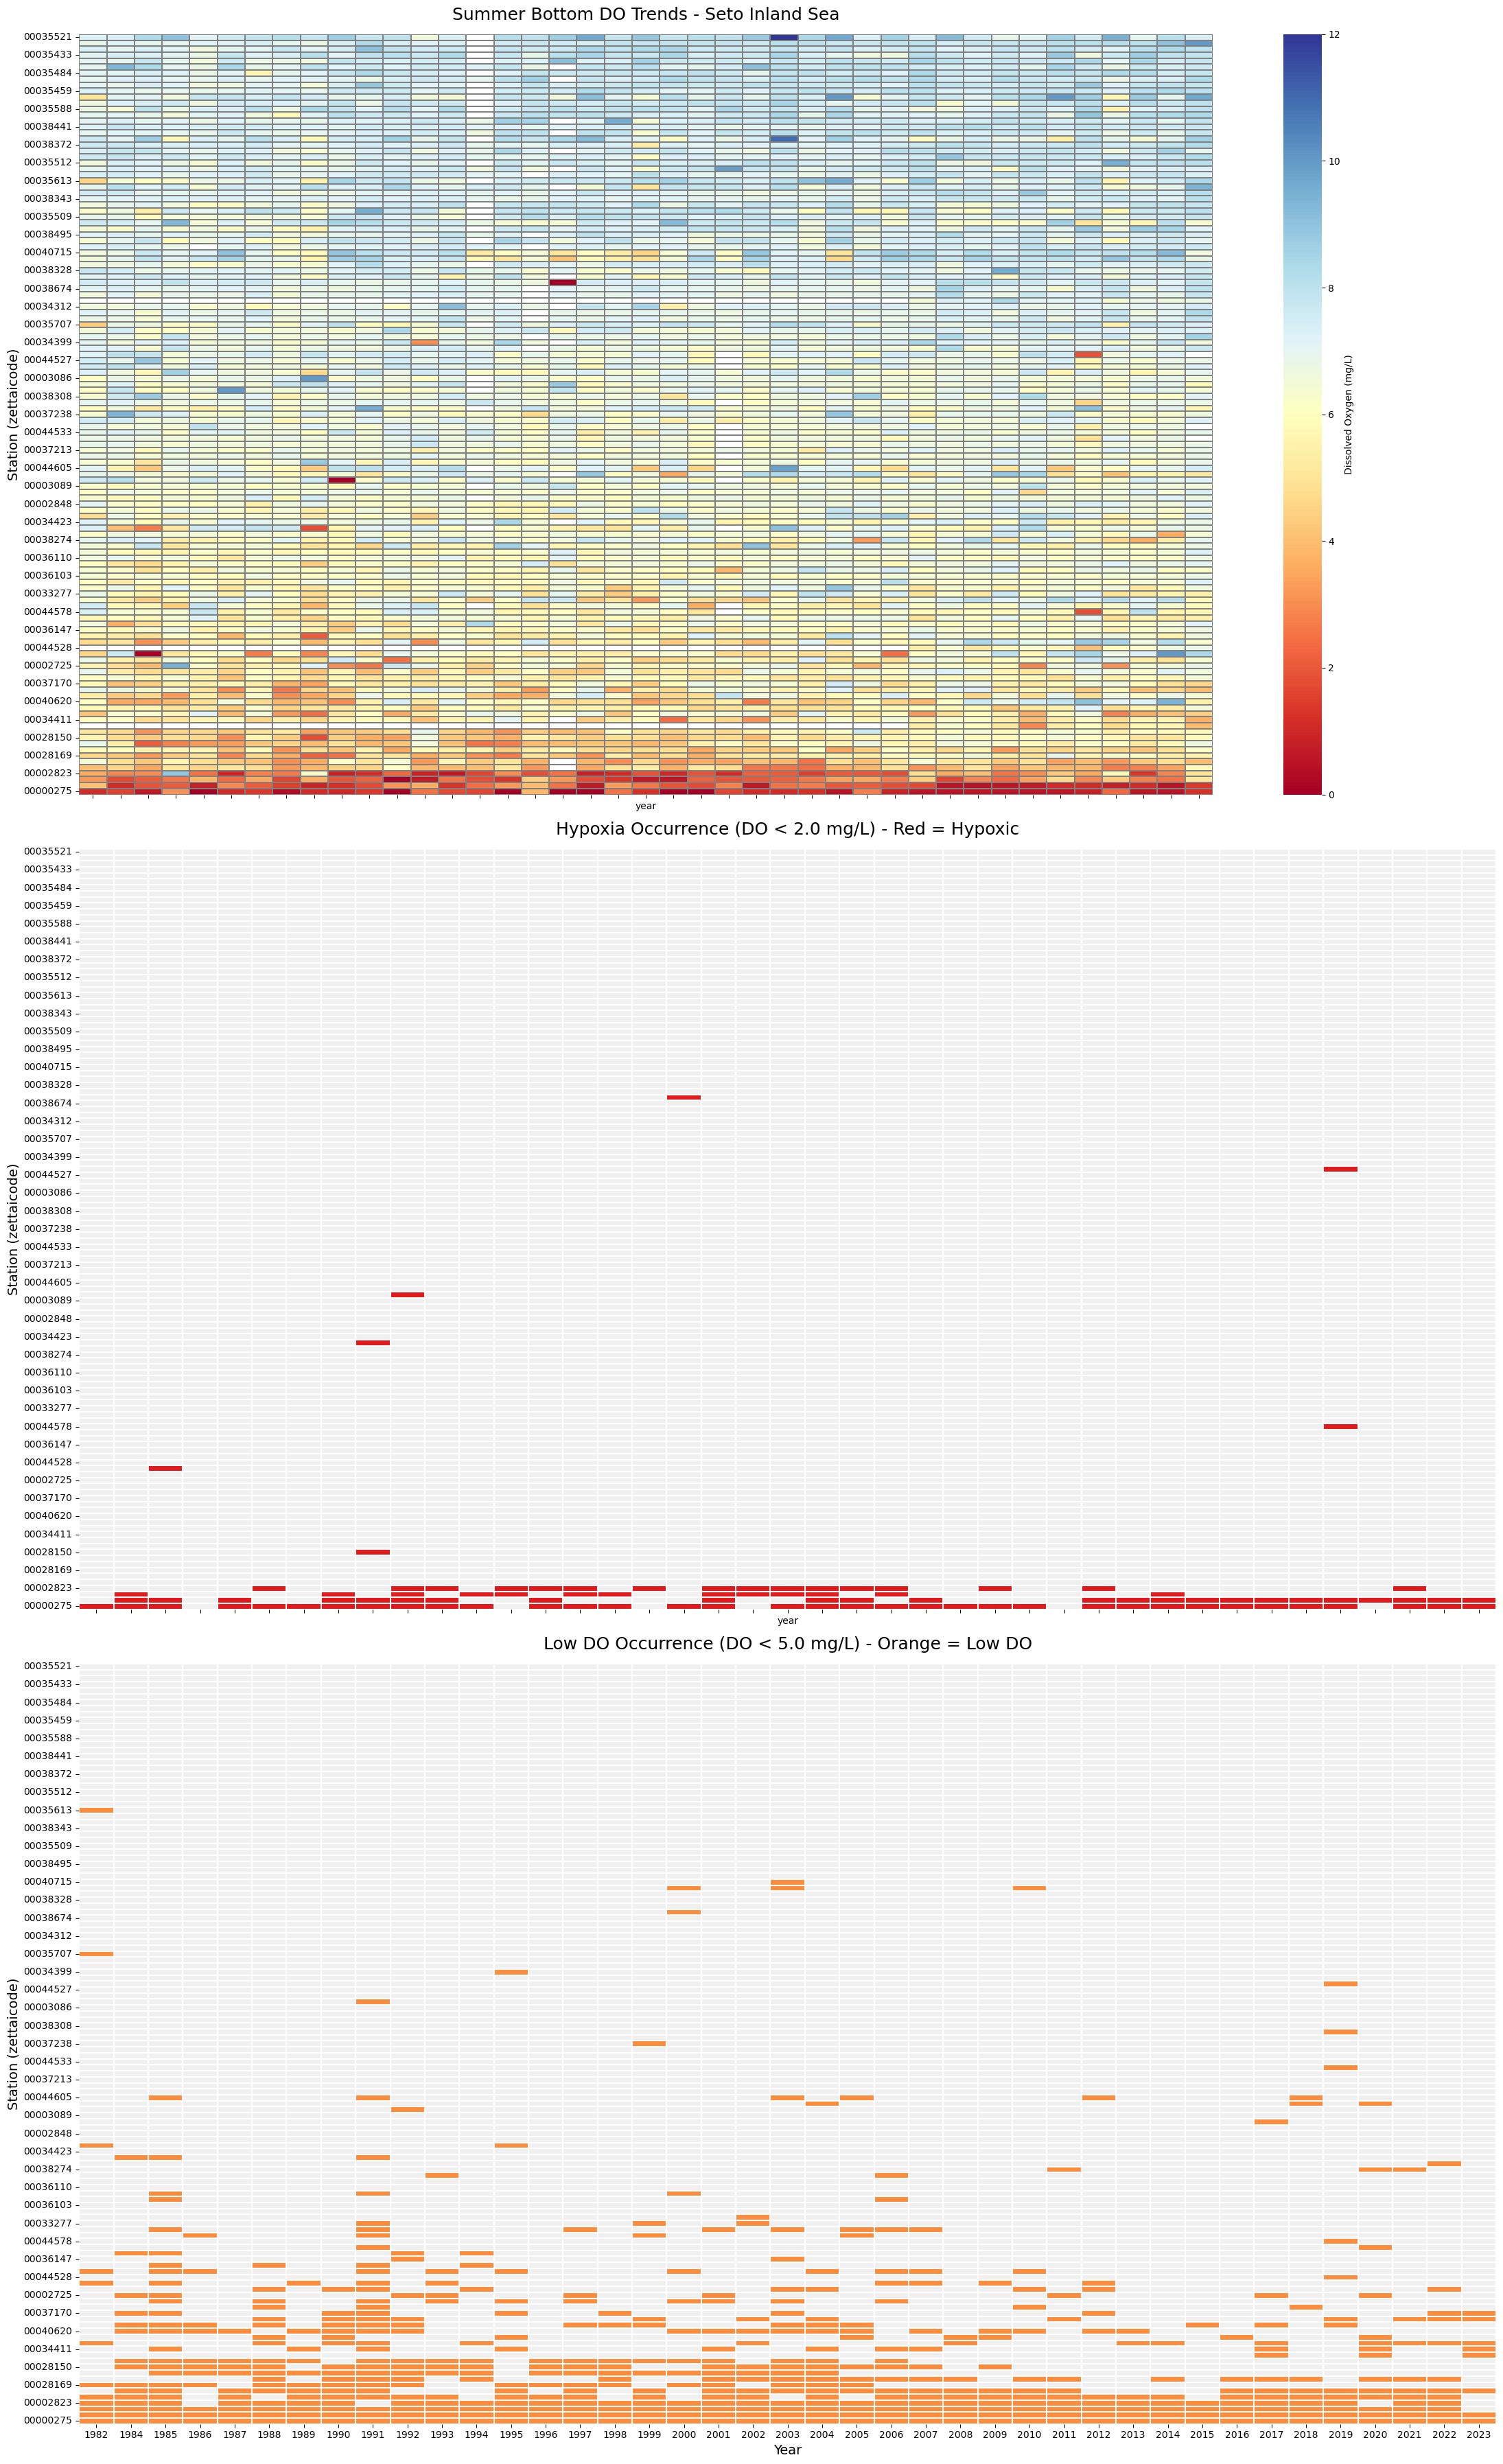

In [27]:
import matplotlib.colors as mcolors

# Define thresholds
HYPOXIA_THRESHOLD = 2.0
LOW_DO_THRESHOLD = 5.0

# Create subplots: 1 column, 3 rows
fig, axes = plt.subplots(3, 1, figsize=(22, 36), sharex=True)

# 1. Original Continuous Heatmap
sns.heatmap(
    pivot_df, 
    cmap='RdYlBu', 
    vmin=0, vmax=12, 
    cbar_kws={'label': 'Dissolved Oxygen (mg/L)'},
    linewidths=0.01,
    linecolor='gray',
    ax=axes[0]
)
axes[0].set_title(f'Summer Bottom DO Trends - {TARGET_REGION}', fontsize=18, pad=15)
axes[0].set_ylabel('Station (zettaicode)', fontsize=14)

# 2. Binary Hypoxia Heatmap (< 2 mg/L)
# Map: 0 (False) to light gray, 1 (True) to Red
hypoxia_mask = (pivot_df < HYPOXIA_THRESHOLD).astype(float)
sns.heatmap(
    hypoxia_mask,
    cmap=mcolors.ListedColormap(['#f0f0f0', '#e31a1c']),
    cbar=False,
    linewidths=0.01,
    linecolor='white',
    ax=axes[1]
)
axes[1].set_title(f'Hypoxia Occurrence (DO < {HYPOXIA_THRESHOLD} mg/L) - Red = Hypoxic', fontsize=18, pad=15)
axes[1].set_ylabel('Station (zettaicode)', fontsize=14)

# 3. Binary Low DO Heatmap (< 5 mg/L)
low_do_mask = (pivot_df < LOW_DO_THRESHOLD).astype(float)
sns.heatmap(
    low_do_mask,
    cmap=mcolors.ListedColormap(['#f0f0f0', '#fd8d3c']),
    cbar=False,
    linewidths=0.01,
    linecolor='white',
    ax=axes[2]
)
axes[2].set_title(f'Low DO Occurrence (DO < {LOW_DO_THRESHOLD} mg/L) - Orange = Low DO', fontsize=18, pad=15)
axes[2].set_xlabel('Year', fontsize=14)
axes[2].set_ylabel('Station (zettaicode)', fontsize=14)

plt.tight_layout()

# Save combined figure
output_path = ProjectPaths.FIGURES_DIR / f'hypoxia_status_comparison_{TARGET_REGION.replace(" ", "_")}.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Comparison plot saved to: {output_path}")

plt.show()


### Geographical Bivariate Analysis: Long-term Trend vs. Recent Severity

To identify areas where hypoxia is worsening or improving, we compare the historical frequency of hypoxia against the most recent decade. This approach uses normalized proportional frequencies to ensure an objective comparison between two timeframes of unequal length.

#### 1. Epoch Partitioning
The analysis partitions the 43-year dataset into two distinct periods:
*   **Historical Baseline ($P_{hist}$):** 1981 – 2013 (33 years)
*   **Recent State ($P_{recent}$):** 2014 – 2023 (10 years)

#### 2. Calculation Method
For each station, we calculate the following metrics using a hypoxia threshold of **5.0 mg/L**:

1.  **Hypoxia Frequency ($P$):** 
    $$P = \frac{\text{Count of Hypoxic Years in Epoch}}{\text{Total Years in Epoch}}$$
    *This represents the probability of hypoxia occurring in any given year during that period.*

2.  **Proportional Delta ($\Delta$):**
    $$\Delta = P_{recent} - P_{hist}$$
    *   **$\Delta > 0$ (Red):** Worsening trend (hypoxia is more frequent now than in the past).
    *   **$\Delta = 0$ (White):** Stable state.
    *   **$\Delta < 0$ (Blue):** Improving trend (hypoxia is less frequent now than in the past).

#### 3. Bivariate Visual Encoding
*   **Marker Color:** Encodes the **Trend ($\Delta$)**. It highlights whether the station's health is trajectorying toward recovery or degradation.
*   **Marker Size:** Encodes the **Recent Severity ($P_{recent}$)**, which is the 2014 - 2023 period only. Larger circles indicate stations that currently experience hypoxia very frequently, providing context to the trend.


In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

# 1. Data Partitioning and Frequency Calculation
# Ensure columns are integers for filtering
years = pivot_df.columns.astype(int)
hist_years = [y for y in years if 1981 <= y <= 2013]
recent_years = [y for y in years if 2014 <= y <= 2023]

# Calculate Normalized Proportional Frequencies (P_hist and P_recent)
# We use the fixed denominators (33 and 10) as requested for normalization
p_hist = (pivot_df[hist_years] < HYPOXIA_THRESHOLD).sum(axis=1) / 33
p_recent = (pivot_df[recent_years] < HYPOXIA_THRESHOLD).sum(axis=1) / 10

# Calculate Proportional Delta (Trend)
delta = p_recent - p_hist

# 2. Extract Geographic Coordinates
# We get the first occurrence of lat/lon for each station from the filtered dataset
coords = summer_bottom.groupby('zettaicode')[['latitude', 'longitude']].first()
coords.index = coords.index.astype(str).str.zfill(8)

# Combine analysis results with coordinates
map_df = pd.DataFrame({
    'delta': delta,
    'p_recent': p_recent,
    'lat': coords['latitude'],
    'lon': coords['longitude']
}).dropna()

# 3. Visualization
plt.figure(figsize=(15, 12))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set map extent based on data
buffer = 0.2
ax.set_extent([map_df['lon'].min()-buffer, map_df['lon'].max()+buffer, 
               map_df['lat'].min()-buffer, map_df['lat'].max()+buffer])

# Add High-Contrast Basemap features
ax.add_feature(cfeature.LAND, facecolor='#f5f5f5', edgecolor='dimgray', zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor='#ffffff', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, color='black', zorder=2)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, alpha=0.3)

# Bivariate Mapping
# Color: Delta (Red-White-Blue divergent)
# Size: P_recent (Scaled for visibility)
vmax = max(abs(map_df['delta'].min()), abs(map_df['delta'].max()), 0.1) # Center at 0
sc = ax.scatter(
    map_df['lon'], map_df['lat'],
    c=map_df['delta'],
    s=map_df['p_recent'] * 1000 + 20, # Scale size for impact, minimum size 20
    cmap='RdBu_r', # Red for positive (worsening), Blue for negative (improving)
    vmin=-vmax, vmax=vmax,
    edgecolors='black',
    linewidths=0.5,
    alpha=0.9,
    transform=ccrs.PlateCarree(),
    zorder=3
)

# Legends
# 1. Continuous Colorbar for Trend (Delta)
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.7, pad=0.08)
cbar.set_label('Proportional Delta (Recent - Historical Frequency)', fontsize=12, labelpad=10)
cbar.ax.set_title('Worsening (Red) \n vs \n Improving (Blue)', fontsize=10, pad=10)

# 2. Discrete Size Legend for Recent Frequency (P_recent)
# Create proxy artists for the size legend
sizes = [0.1, 0.5, 1.0]
labels = ['10% frequency', '50% frequency', '100% frequency']
legend_elements = [Line2D([0], [0], marker='o', color='w', label=l,
                          markerfacecolor='gray', markersize=np.sqrt(s * 1000 + 20),
                          markeredgecolor='k', alpha=0.6)
                   for s, l in zip(sizes, labels)]

size_legend = ax.legend(handles=legend_elements, loc='lower right', 
                        title='Recent State (2014-2023)\nHypoxia Frequency',
                        frameon=True, fontsize=10, bbox_to_anchor=(0.98, 0.02))
ax.add_artist(size_legend)

plt.title(f'Bivariate Hypoxia Analysis: Trend (Color) and Recent Severity (Size)\n{TARGET_REGION} (Summer Bottom)', 
          fontsize=18, fontweight="bold", pad=20)

# Save result
map_output = ProjectPaths.FIGURES_DIR / f'hypoxia_bivariate_map_{TARGET_REGION.replace(" ", "_")}.png'
plt.savefig(map_output, dpi=300, bbox_inches='tight')
print(f"Bivariate map saved to: {map_output}")

plt.show()

/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


Bivariate map saved to: /home/reyha/SIS_Analysis_WSL/figures/lowDO_bivariate_map_Seto_Inland_Sea.png


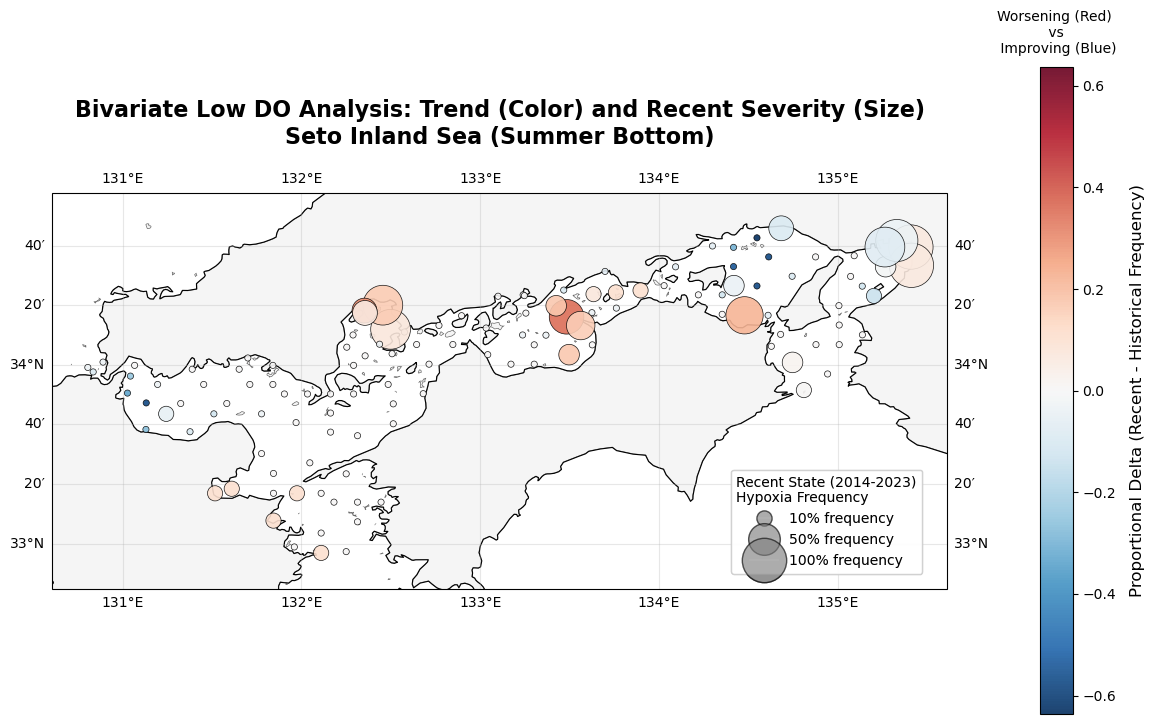

In [37]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

# 1. Data Partitioning and Frequency Calculation
# Ensure columns are integers for filtering
years = pivot_df.columns.astype(int)
hist_years = [y for y in years if 1981 <= y <= 2013]
recent_years = [y for y in years if 2014 <= y <= 2023]

# Calculate Normalized Proportional Frequencies (P_hist and P_recent)
# We use the fixed denominators (33 and 10) as requested for normalization
p_hist = (pivot_df[hist_years] < LOW_DO_THRESHOLD).sum(axis=1) / 33
p_recent = (pivot_df[recent_years] < LOW_DO_THRESHOLD).sum(axis=1) / 10

# Calculate Proportional Delta (Trend)
delta = p_recent - p_hist

# 2. Extract Geographic Coordinates
# We get the first occurrence of lat/lon for each station from the filtered dataset
coords = summer_bottom.groupby('zettaicode')[['latitude', 'longitude']].first()
coords.index = coords.index.astype(str).str.zfill(8)

# Combine analysis results with coordinates
map_df = pd.DataFrame({
    'delta': delta,
    'p_recent': p_recent,
    'lat': coords['latitude'],
    'lon': coords['longitude']
}).dropna()

# 3. Visualization
plt.figure(figsize=(15, 12))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set map extent based on data
buffer = 0.2
ax.set_extent([map_df['lon'].min()-buffer, map_df['lon'].max()+buffer, 
               map_df['lat'].min()-buffer, map_df['lat'].max()+buffer])

# Add High-Contrast Basemap features
ax.add_feature(cfeature.LAND, facecolor='#f5f5f5', edgecolor='dimgray', zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor='#ffffff', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, color='black', zorder=2)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, alpha=0.3)

# Bivariate Mapping
# Color: Delta (Red-White-Blue divergent)
# Size: P_recent (Scaled for visibility)
vmax = max(abs(map_df['delta'].min()), abs(map_df['delta'].max()), 0.1) # Center at 0
sc = ax.scatter(
    map_df['lon'], map_df['lat'],
    c=map_df['delta'],
    s=map_df['p_recent'] * 1000 + 20, # Scale size for impact, minimum size 20
    cmap='RdBu_r', # Red for positive (worsening), Blue for negative (improving)
    vmin=-vmax, vmax=vmax,
    edgecolors='black',
    linewidths=0.5,
    alpha=0.9,
    transform=ccrs.PlateCarree(),
    zorder=3
)

# Legends
# 1. Continuous Colorbar for Trend (Delta)
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.7, pad=0.08)
cbar.set_label('Proportional Delta (Recent - Historical Frequency)', fontsize=12, labelpad=10)
cbar.ax.set_title('Worsening (Red) \n vs \n Improving (Blue)', fontsize=10, pad=10)

# 2. Discrete Size Legend for Recent Frequency (P_recent)
# Create proxy artists for the size legend
sizes = [0.1, 0.5, 1.0]
labels = ['10% frequency', '50% frequency', '100% frequency']
legend_elements = [Line2D([0], [0], marker='o', color='w', label=l,
                          markerfacecolor='gray', markersize=np.sqrt(s * 1000 + 20),
                          markeredgecolor='k', alpha=0.6)
                   for s, l in zip(sizes, labels)]

size_legend = ax.legend(handles=legend_elements, loc='lower right', 
                        title='Recent State (2014-2023)\nHypoxia Frequency',
                        frameon=True, fontsize=10, bbox_to_anchor=(0.98, 0.02))
ax.add_artist(size_legend)

plt.title(f'Bivariate Low DO Analysis: Trend (Color) and Recent Severity (Size)\n{TARGET_REGION} (Summer Bottom)', 
          fontsize=16, fontweight="bold", pad=20)

# Save result
map_output = ProjectPaths.FIGURES_DIR / f'lowDO_bivariate_map_{TARGET_REGION.replace(" ", "_")}.png'
plt.savefig(map_output, dpi=300, bbox_inches='tight')
print(f"Bivariate map saved to: {map_output}")

plt.show()

## 3. Statistical Trend (Slope)

To quantify the "tendency", we calculate the linear slope of DO vs Year for each station. 
- **Positive slope**: DO is increasing (Improvement)
- **Negative slope**: DO is decreasing (Worsening hypoxia)

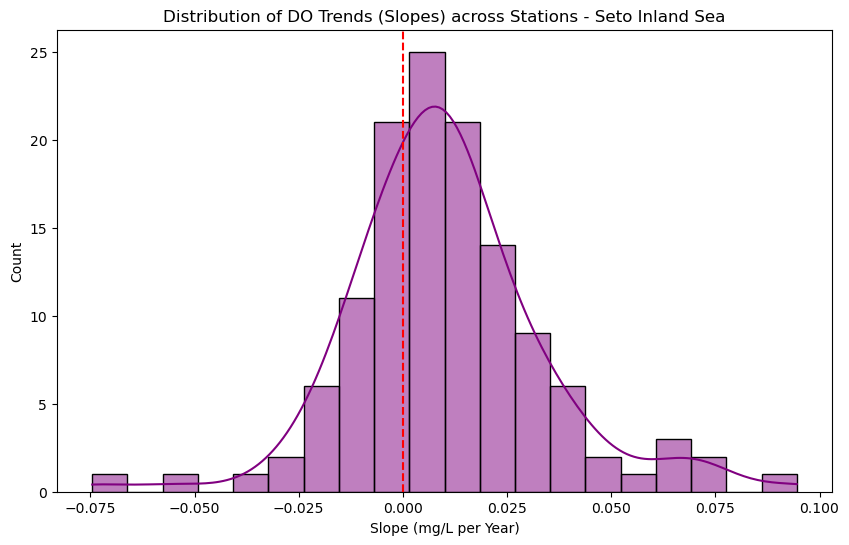

Stations with worsening trend: 41
Stations with improving trend: 86


In [26]:
def calculate_slope(row):
    valid_mask = row.notna()
    if valid_mask.sum() < 10:  # Require at least 10 years of data
        return np.nan
    
    years = row.index[valid_mask].astype(float)
    values = row[valid_mask].values
    slope, intercept, r_value, p_value, std_err = stats.linregress(years, values)
    return slope

slopes = pivot_df.apply(calculate_slope, axis=1).dropna()

plt.figure(figsize=(10, 6))
sns.histplot(slopes, bins=20, kde=True, color='purple')
plt.axvline(0, color='red', linestyle='--')
plt.title(f'Distribution of DO Trends (Slopes) across Stations - {TARGET_REGION}')
plt.xlabel('Slope (mg/L per Year)')
plt.ylabel('Count')
plt.show()

worsening = slopes[slopes < 0]
improving = slopes[slopes > 0]

print(f"Stations with worsening trend: {len(worsening)}")
print(f"Stations with improving trend: {len(improving)}")

Statistical plot saved to: /home/reyha/SIS_Analysis_WSL/figures/hypoxia_trend_vs_decorr_filtered_Seto_Inland_Sea.png


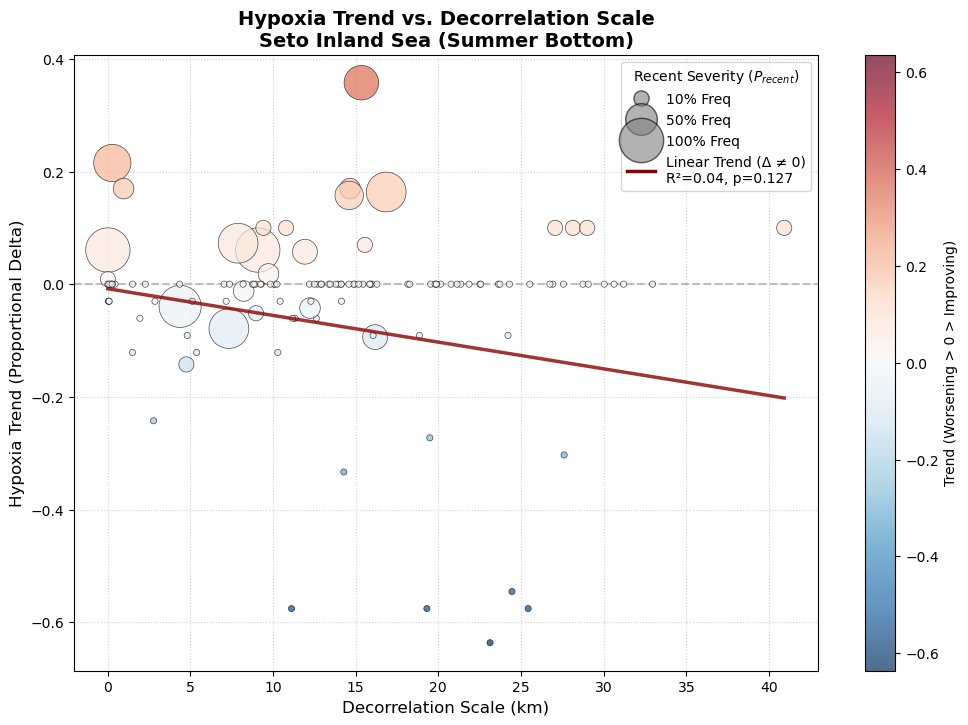

Full Correlation: -0.098
Filtered Correlation (Δ ≠ 0): -0.208


In [41]:
# --- Option 1: Statistical Relationship between Trend and Decorrelation Scale ---

# 1. Load Decorrelation Scale Data
subset_dir = ProjectPaths.get_subset_dir('Summer', 'bottom')
decorr_file = subset_dir / "stations_decorrelation_scale.csv"

if not decorr_file.exists():
    print(f"Warning: {decorr_file} not found. Please ensure the decorrelation pipeline has run.")
else:
    df_decorr = pd.read_csv(decorr_file, dtype={'Station_ID': str})
    df_decorr['Station_ID'] = df_decorr['Station_ID'].str.zfill(8)

    # 2. Merge with existing map_df (which contains delta and p_recent)
    stats_df = map_df.merge(
        df_decorr[['Station_ID', 'Decorrelation_Scale_km']], 
        left_index=True, 
        right_on='Station_ID', 
        how='inner'
    )

    # 3. Visualization
    plt.figure(figsize=(12, 8))
    
    # Color limits centered at 0
    vmax = max(abs(stats_df['delta'].min()), abs(stats_df['delta'].max()), 0.1)

    # Filter for stations with non-zero delta for trend calculation
    trend_df = stats_df[stats_df['delta'] != 0].dropna(subset=['Decorrelation_Scale_km', 'delta'])

    sc = plt.scatter(
        stats_df['Decorrelation_Scale_km'], 
        stats_df['delta'],
        c=stats_df['delta'],
        s=stats_df['p_recent'] * 1000 + 20, 
        cmap='RdBu_r', 
        vmin=-vmax, vmax=vmax,
        edgecolors='black', 
        linewidths=0.5, 
        alpha=0.7,
        zorder=2
    )

    # Add Trend Line for non-zero delta stations
    if len(trend_df) > 1:
        from scipy import stats as sp_stats
        slope, intercept, r_value, p_value, std_err = sp_stats.linregress(trend_df['Decorrelation_Scale_km'], trend_df['delta'])
        x_line = np.linspace(stats_df['Decorrelation_Scale_km'].min(), stats_df['Decorrelation_Scale_km'].max(), 100)
        y_line = slope * x_line + intercept
        plt.plot(x_line, y_line, color='darkred', alpha=0.8, lw=2.5, zorder=3,
                 label=f'Trend (Δ ≠ 0)\nR²={r_value**2:.2f}, p={p_value:.3f}')

    # Add reference line at Delta = 0
    plt.axhline(0, color='gray', linestyle='--', alpha=0.5, zorder=1)
    
    # Labels and Title
    plt.xlabel('Decorrelation Scale (km)', fontsize=12)
    plt.ylabel('Hypoxia Trend (Proportional Delta)', fontsize=12)
    plt.title(f'Hypoxia Trend vs. Decorrelation Scale\n{TARGET_REGION} (Summer Bottom)', fontsize=14, fontweight='bold')

    # Legends
    cbar = plt.colorbar(sc)
    cbar.set_label('Trend (Worsening > 0 > Improving)', fontsize=10)
    
    # Size Legend + Trend Legend
    sizes = [0.1, 0.5, 1.0]
    labels = ['10% Freq', '50% Freq', '100% Freq']
    legend_elements = [Line2D([0], [0], marker='o', color='w', label=l,
                              markerfacecolor='gray', markersize=np.sqrt(s * 1000 + 20),
                              markeredgecolor='k', alpha=0.6)
                       for s, l in zip(sizes, labels)]
    
    if len(trend_df) > 1:
        legend_elements.append(Line2D([0], [0], color='darkred', lw=2.5, 
                                     label=f'Linear Trend (Δ ≠ 0)\nR²={r_value**2:.2f}, p={p_value:.3f}'))

    plt.legend(handles=legend_elements, loc='upper right', title='Recent Severity ($P_{recent}$)')

    plt.grid(True, linestyle=':', alpha=0.6)
    
    # Save result
    stats_output = ProjectPaths.FIGURES_DIR / f'hypoxia_trend_vs_decorr_filtered_{TARGET_REGION.replace(" ", "_")}.png'
    plt.savefig(stats_output, dpi=300, bbox_inches='tight')
    print(f"Statistical plot saved to: {stats_output}")

    plt.show()

    # Quick Correlation Printout
    full_corr = stats_df['Decorrelation_Scale_km'].corr(stats_df['delta'])
    filtered_corr = trend_df['Decorrelation_Scale_km'].corr(trend_df['delta'])
    print(f"Full Correlation: {full_corr:.3f}")
    print(f"Filtered Correlation (Δ ≠ 0): {filtered_corr:.3f}")